In [1]:

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset, concatenate_datasets
from transformers import CLIPModel, AutoProcessor
from sklearn.decomposition import PCA
from tqdm.auto import tqdm
from IPython.display import display

print("Everything imported successfully!")



Everything imported successfully!


In [2]:

import sys

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)


Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
PyTorch version: 2.15.0+cpu
Device: cpu


In [3]:
fairface = load_dataset(
    "HuggingFaceM4/FairFace",
    "0.25"
)

# Combine training and validation
dataset = concatenate_datasets([
    fairface["train"],
    fairface["validation"]
])

# Keep only ages 20+
dataset = dataset.filter(
    lambda age: age >= 3,
    input_columns=["age"]
)

print("Total adult images:", len(dataset))


Total adult images: 73659


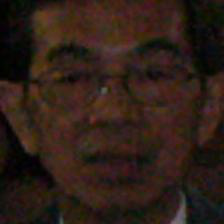

Age: 50-59
Gender: Male
Ethnicity: East Asian


In [4]:
##First picture
image = dataset[0]["image"]

display(image)

print("Age:", dataset.features["age"].int2str(dataset[0]["age"]))
print("Gender:", dataset.features["gender"].int2str(dataset[0]["gender"]))
print("Ethnicity:", dataset.features["race"].int2str(dataset[0]["race"]))


## How many people in each group

In [5]:

metadata = pd.DataFrame({
    "gender": [
        dataset.features["gender"].int2str(x)
        for x in dataset["gender"]
    ],
    "age": [
        dataset.features["age"].int2str(x)
        for x in dataset["age"]
    ],
    "race": [
        dataset.features["race"].int2str(x)
        for x in dataset["race"]
    ]
})

print("Gender counts:")
print(metadata["gender"].value_counts())

print("\nEthnicity counts:")
print(metadata["race"].value_counts())

print("\nAge counts:")
print(metadata["age"].value_counts())


Gender counts:
gender
Male      39390
Female    34269
Name: count, dtype: int64

Ethnicity counts:
race
White              15421
Latino_Hispanic    11191
Indian             10220
East Asian         10103
Black               9436
Southeast Asian     8664
Middle Eastern      8624
Name: count, dtype: int64

Age counts:
age
20-29           28898
30-39           21580
40-49           12097
50-59            7024
60-69            3100
more than 70      960
Name: count, dtype: int64


In [6]:

model_name = "openai/clip-vit-base-patch32"

model = CLIPModel.from_pretrained(model_name)
processor = AutoProcessor.from_pretrained(model_name)

model = model.to(device)
model.eval()

print("CLIP model loaded successfully!")


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP model loaded successfully!


In [7]:
##Ocupations

occupations = [
    "doctor",
    "nurse",
    "engineer",
    "scientist",
    "professor",
    "teacher",
    "artist",
    "athlete"
]





In [8]:

def make_prompt(job):
    article = "an" if job[0].lower() in "aeiou" else "a"
    return f"a portrait photo of {article} {job}"

prompts = [make_prompt(job) for job in occupations]

print(prompts)


['a portrait photo of a doctor', 'a portrait photo of a nurse', 'a portrait photo of an engineer', 'a portrait photo of a scientist', 'a portrait photo of a professor', 'a portrait photo of a teacher', 'a portrait photo of an artist', 'a portrait photo of an athlete']


In [9]:
##Test one picture

test_image = dataset[0]["image"]

inputs = processor(
    text=prompts,
    images=test_image,
    return_tensors="pt",
    padding=True
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

with torch.inference_mode():
    outputs = model(**inputs)

scores = outputs.logits_per_image[0].cpu().numpy()

test_results = pd.DataFrame({
    "occupation": occupations,
    "score": scores
})

display(
    test_results.sort_values(
        "score", ascending=False
    )
)


,occupation,score
4,professor,28.149115
5,teacher,27.704086
2,engineer,27.065762
0,doctor,26.757570
3,scientist,26.328098
6,artist,26.245224
7,athlete,25.011280
1,nurse,22.389387


In [10]:
##Testing more pictures

# First test with 200 pictures.
# When everything works, change N to len(dataset).

N = len(dataset)

rng = np.random.default_rng(42)

selected_indices = rng.permutation(
    len(dataset)
)[:N]

BATCH_SIZE = 16

print("Pictures to test:", N)


Pictures to test: 73659


## Turn job descriptions into embeddings

In [11]:
##Turn job descriptions into embeddings
import torch.nn.functional as F

def get_features_tensor(output):
    if hasattr(output, "pooler_output"):
        return output.pooler_output
    if isinstance(output, (tuple, list)):
        return output[0]
    return output

text_inputs = processor(
    text=prompts,
    return_tensors="pt",
    padding=True
)

text_inputs = {
    key: value.to(device)
    for key, value in text_inputs.items()
}

with torch.inference_mode():
    text_features = get_features_tensor(
        model.get_text_features(**text_inputs)
    )
    text_features = F.normalize(
        text_features, dim=-1
    )

text_embeddings = text_features.cpu().numpy()

print("Text embeddings:", text_embeddings.shape)


Text embeddings: (8, 512)


In [12]:

all_embeddings = []

for start in tqdm(range(0, N, BATCH_SIZE)):

    batch_ids = selected_indices[
        start:start + BATCH_SIZE
    ]

    images = [
        dataset[int(i)]["image"]
        for i in batch_ids
    ]

    image_inputs = processor(
        images=images,
        return_tensors="pt"
    )

    pixels = image_inputs["pixel_values"].to(device)

    with torch.inference_mode():
        features = get_features_tensor(
            model.get_image_features(
                pixel_values=pixels
            )
        )

        features = F.normalize(
            features, dim=-1
        )

    all_embeddings.append(
        features.cpu().numpy()
    )

image_embeddings = np.vstack(all_embeddings)

print("Finished processing:", len(image_embeddings))


  0%|          | 0/4604 [00:00<?, ?it/s]

Finished processing: 73659


## Compare image embeddings with text embeddings

In [13]:
#Compare image embeddings with text embeddings
similarities = image_embeddings @ text_embeddings.T

best_job_ids = similarities.argmax(axis=1)

predicted_jobs = np.array(occupations)[best_job_ids]

results = metadata.iloc[
    selected_indices
].reset_index(drop=True).copy()

results.insert(
    0, "image_index", selected_indices
)

results["predicted_job"] = predicted_jobs

for i, job in enumerate(occupations):
    results[f"sim_{job}"] = similarities[:, i]

display(results.head())


,image_index,gender,age,race,predicted_job,sim_doctor,sim_nurse,sim_engineer,sim_scientist,sim_professor,sim_teacher,sim_artist,sim_athlete
0,15309,Female,20-29,Indian,artist,0.204169,0.207816,0.216298,0.204547,0.210466,0.206900,0.228829,0.213027
1,48813,Female,20-29,East Asian,teacher,0.235102,0.256633,0.242174,0.232046,0.233757,0.257279,0.254496,0.255129
2,56083,Female,30-39,Indian,athlete,0.205626,0.194901,0.214839,0.198493,0.204334,0.206693,0.220961,0.229560
3,28196,Male,20-29,White,artist,0.213636,0.192452,0.227374,0.220767,0.222244,0.221878,0.228624,0.219579
4,46922,Male,30-39,Indian,athlete,0.240235,0.228639,0.249725,0.227048,0.239376,0.253914,0.232285,0.261715


In [14]:
##Save the results

results.to_csv("clip_results.csv", index=False)

np.save(
    "clip_image_embeddings.npy",
    image_embeddings
)

np.save(
    "clip_text_embeddings.npy",
    text_embeddings
)

print("Results saved successfully!")


Results saved successfully!


## Gender comparison chart

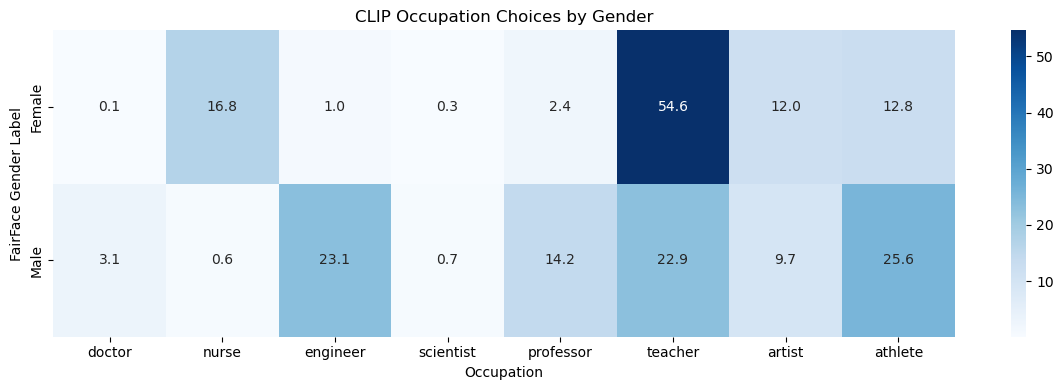

In [15]:
##Gender comparison chart

gender_table = pd.crosstab(
    results["gender"],
    results["predicted_job"],
    normalize="index"
)

gender_table = (
    gender_table.reindex(
        columns=occupations,
        fill_value=0
    ) * 100
)

plt.figure(figsize=(12, 4))

sns.heatmap(
    gender_table,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("CLIP Occupation Choices by Gender")
plt.xlabel("Occupation")
plt.ylabel("FairFace Gender Label")

plt.tight_layout()
plt.savefig("gender_heatmap.png", dpi=200)
plt.show()


What the gender heatmap tells us (actual saved results)
- Teacher: CLIP selects teacher for 54.6% of female-labeled faces, but only 22.9% of male-labeled faces. This is a 31.7 percentage-point difference.
- Athlete: CLIP selects athlete for 25.6% of male-labeled faces and 12.8% of female-labeled faces. This is a 12.8-point difference in the other direction.
- Engineer: CLIP selects engineer for 23.1% of male-labeled faces and only 1.0% of female-labeled faces (about 22.1 points apart).
- Nurse: Female-labeled faces are selected much more often (16.8%) than male-labeled faces (0.6%).
  
Why might CLIP choose “teacher” for just over half of the female-labeled faces? One possible explanation is that CLIP has learned a common visual-language stereotype connecting women to teaching and nursing. A similar possible stereotype connects men to sports or engineering. But we have not proved the cause. The images can also differ in age, glasses, hairstyle, clothing, or background.

What makes this worth investigating? These are not just a few examples: the differences appear across thousands of images. Later, we test smaller gender × ethnicity groups, age groups, and different text prompts to see when the pattern becomes stronger or weaker.

Important: A 54.6% “teacher” result does not mean a 54.6% probability that a person is a teacher. CLIP is forced to pick one of eight text descriptions. The row percentages add up to 100%, so if one job becomes more common, some other job must become less common.

teacher: Male - Female = -31.7 percentage points
athlete: Male - Female = 12.8 percentage points
engineer: Male - Female = 22.1 percentage points


,occupation,gender,count_of_faces,chosen_percent
0,teacher,Female,34269,54.64
1,teacher,Male,39390,22.90
2,athlete,Female,34269,12.79
3,athlete,Male,39390,25.60
4,engineer,Female,34269,1.03
5,engineer,Male,39390,23.13


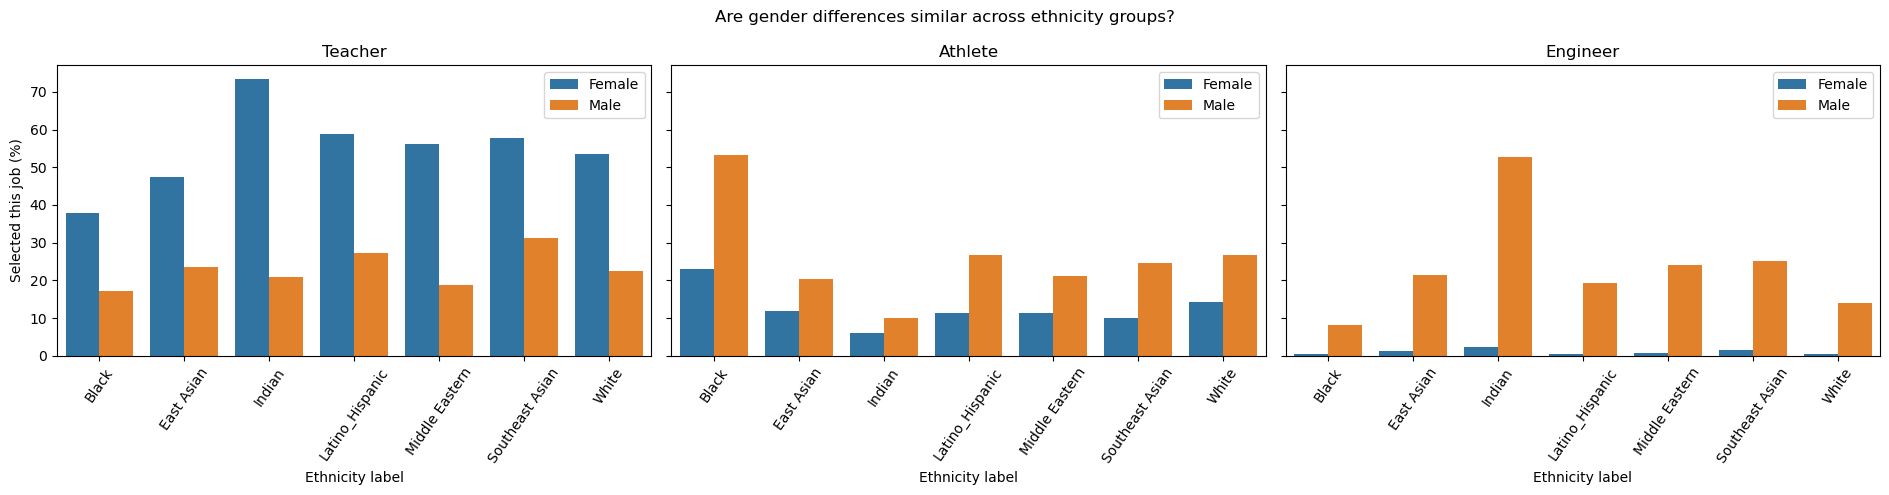

In [16]:
# Look at teacher, athlete, and engineer together.
# "difference" means male percentage minus female percentage.
focus_jobs = ["teacher", "athlete", "engineer"]
focus_rows = []

for job in focus_jobs:
    rates = {}
    for gender in ["Female", "Male"]:
        selected = results.loc[results["gender"] == gender, "predicted_job"]
        rates[gender] = (selected == job).mean() * 100
        focus_rows.append({
            "occupation": job,
            "gender": gender,
            "count_of_faces": len(selected),
            "chosen_percent": rates[gender]
        })
    print(f"{job}: Male - Female = {rates['Male']-rates['Female']:.1f} percentage points")

display(pd.DataFrame(focus_rows).round(2))

# Look at BOTH gender and ethnicity. This is stronger than one overall chart.
rows = []
for job in focus_jobs:
    for (race, gender), group in results.groupby(["race", "gender"]):
        rows.append({
            "occupation": job,
            "race": race,
            "gender": gender,
            "percentage": (group["predicted_job"] == job).mean() * 100,
            "count": len(group)
        })

focus_subgroups = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(19, 5), sharey=True)
for ax, job in zip(axes, focus_jobs):
    sns.barplot(data=focus_subgroups.query("occupation == @job"),
                x="race", y="percentage", hue="gender", ax=ax)
    ax.set_title(job.title())
    ax.set_xlabel("Ethnicity label")
    ax.set_ylabel("Selected this job (%)")
    ax.tick_params(axis="x", rotation=55)
    ax.legend(loc="upper right")
plt.suptitle("Are gender differences similar across ethnicity groups?")
plt.tight_layout()
plt.savefig("teacher_athlete_engineer_subgroups.png", dpi=200)
plt.show()

## Ethnicity comparison chart

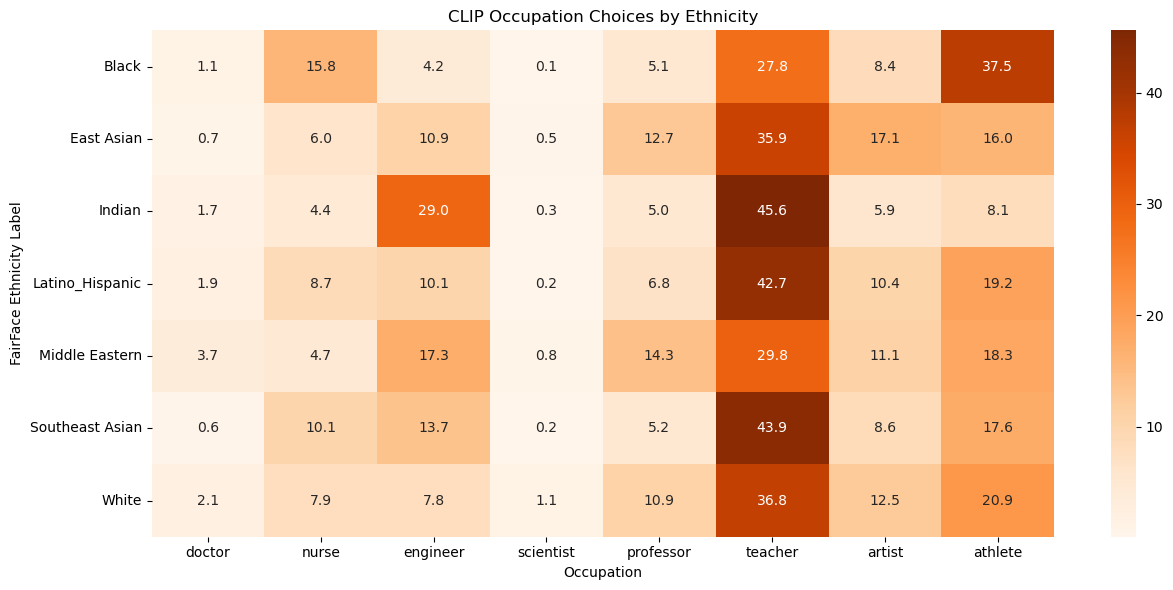

In [17]:
##Ethnicity comparison chart

race_table = pd.crosstab(
    results["race"],
    results["predicted_job"],
    normalize="index"
)

race_table = (
    race_table.reindex(
        columns=occupations,
        fill_value=0
    ) * 100
)

plt.figure(figsize=(13, 6))

sns.heatmap(
    race_table,
    annot=True,
    fmt=".1f",
    cmap="Oranges"
)

plt.title("CLIP Occupation Choices by Ethnicity")
plt.xlabel("Occupation")
plt.ylabel("FairFace Ethnicity Label")

plt.tight_layout()
plt.savefig("race_heatmap.png", dpi=200)
plt.show()


Reading the ethnicity heatmap (actual saved results)
Your chart suggests different associations for different FairFace ethnicity groups:
- Athlete: 37.5% of Black-labeled faces versus 8.1% of Indian-labeled faces. That is a 29.4 percentage-point difference. This is a large difference and a good topic for a deeper investigation.
- Engineer: 29.0% of Indian-labeled faces versus 4.2% of Black-labeled faces. That is a 24.8-point difference.
- Teacher: Indian-labeled faces have 45.6%, Latino/Hispanic-labeled faces 42.7%, and Southeast Asian-labeled faces 43.9%, while Black-labeled faces have 27.8%.
- Scientist: CLIP almost never picks this as the top job for any group: the row values range from 0.1% to 1.1%. This does not mean the model has no scientist association. It may simply prefer another job from this specific list of eight.
- Similar results: The athlete share for East Asian (16.0%) and Middle Eastern (18.3%) labels is quite close. The teacher share for East Asian (35.9%) and White (36.8%) labels is also close.
How big are the differences? The athlete and engineer differences above are much larger than the 2.3- and 0.9-point examples of nearly equal groups. Some jobs change a lot across groups; others change very little.

These are raw comparisons. The ethnic groups do not have exactly the same age and gender mix. For instance, the dataset contains 6,090 male-labeled and 2,534 female-labeled Middle Eastern faces, so gender could partly explain an overall ethnicity difference. We should compare ethnicity within gender and age groups before claiming a specific ethnicity association.

Next question: Which ethnicity differences still appear if we split the data by gender? And does the scientist similarity score differ even when scientist rarely wins?

# Check selection rates inside each gender group.

In [18]:
# Check selection rates inside each gender group.
for job in ["athlete", "engineer", "teacher", "scientist"]:
    table = pd.crosstab(
        [results["race"], results["gender"]],
        results["predicted_job"],
        normalize="index"
    )
    if job in table:
        print("\nOccupation:", job)
        display((100 * table[job]).rename("selected_percent").round(1).to_frame())

# Scientist may have a similarity score even when it is never selected.
scientist_detail = results.groupby("race").agg(
    face_count=("image_index", "size"),
    mean_scientist_similarity=("sim_scientist", "mean"),
    scientist_selected_percent=("predicted_job", lambda s: 100*(s=="scientist").mean())
).sort_values("mean_scientist_similarity", ascending=False)

display(scientist_detail.round(3))


Occupation: athlete


selected_percent
race            gender                  
Black           Female              23.0
                Male                53.2
East Asian      Female              12.0
                Male                20.4
Indian          Female               6.0
                Male                10.0
Latino_Hispanic Female              11.3
                Male                26.7
Middle Eastern  Female              11.2
                Male                21.2
Southeast Asian Female              10.0
                Male                24.7
White           Female              14.3
                Male                26.6


Occupation: engineer


selected_percent
race            gender                  
Black           Female               0.5
                Male                 8.1
East Asian      Female               1.3
                Male                21.5
Indian          Female               2.3
                Male                52.6
Latino_Hispanic Female               0.5
                Male                19.2
Middle Eastern  Female               0.8
                Male                24.1
Southeast Asian Female               1.4
                Male                25.1
White           Female               0.6
                Male                14.0


Occupation: teacher


selected_percent
race            gender                  
Black           Female              37.8
                Male                17.1
East Asian      Female              47.3
                Male                23.5
Indian          Female              73.4
                Male                21.0
Latino_Hispanic Female              58.9
                Male                27.2
Middle Eastern  Female              56.3
                Male                18.8
Southeast Asian Female              57.6
                Male                31.2
White           Female              53.5
                Male                22.5


Occupation: scientist


selected_percent
race            gender                  
Black           Female               0.2
                Male                 0.1
East Asian      Female               0.4
                Male                 0.7
Indian          Female               0.3
                Male                 0.3
Latino_Hispanic Female               0.1
                Male                 0.4
Middle Eastern  Female               0.3
                Male                 1.0
Southeast Asian Female               0.1
                Male                 0.2
White           Female               0.4
                Male                 1.7

,face_count,mean_scientist_similarity,scientist_selected_percent
race,,,
Indian,10220,0.243,0.313
East Asian,10103,0.242,0.505
White,15421,0.239,1.089
Southeast Asian,8664,0.238,0.150
Middle Eastern,8624,0.238,0.777
Latino_Hispanic,11191,0.236,0.241
Black,9436,0.230,0.117


A deeper look at the “scientist” question
The ethnicity chart makes “scientist” look almost absent, but the full similarity scores tell a more interesting story. Mean scientist similarity is about 0.243 for Indian-labeled, 0.242 for East Asian-labeled, and 0.230 for Black-labeled faces. These values are fairly close, even while scientist is hardly ever the top choice (for Black-labeled faces it is 0.1% in this run).

Why the difference between scores and choices? CLIP might give a face a reasonable scientist score, but give teacher, engineer, athlete, or professor an even higher score. The top-choice heatmap loses this extra information. This is exactly why a deeper analysis should look at both the winning occupation and the similarity scores.

The within-gender tables also show that athlete remains higher for Black-labeled faces than Indian-labeled faces: 53.2% vs 10.0% among male-labeled faces and 23.0% vs 6.0% among female-labeled faces. So the overall ethnicity difference is not explained only by having a different male/female mix. Age and visual details still need checking.

# Investigate athlete predictions by ethnicity, age and gender

,gender,race,age,rate,count,percentage
0,Female,Black,20-29,0.4,1987,35.8
12,Male,Black,20-29,0.7,1587,71.5
18,Male,Indian,20-29,0.1,1537,14.8
6,Female,Indian,20-29,0.1,1923,9.1
13,Male,Black,30-39,0.6,1469,58.5
7,Female,Indian,30-39,0.1,1323,5.7
19,Male,Indian,30-39,0.1,1796,11.6
1,Female,Black,30-39,0.2,1487,20.5
8,Female,Indian,40-49,0.0,746,3.6
2,Female,Black,40-49,0.1,759,9.9


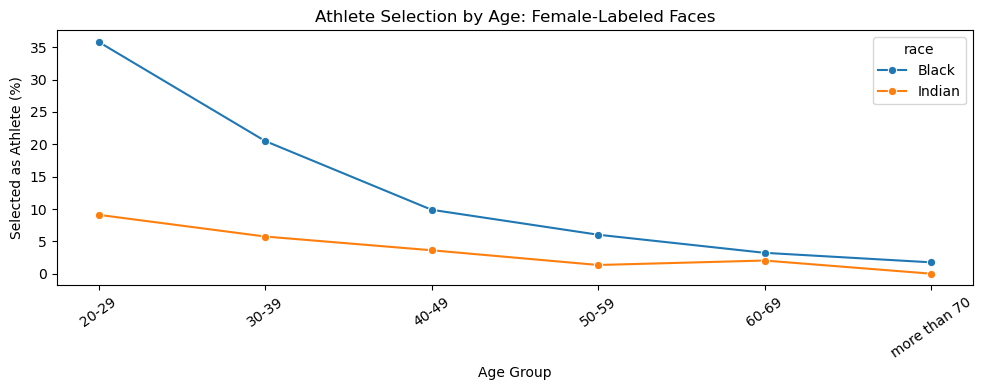

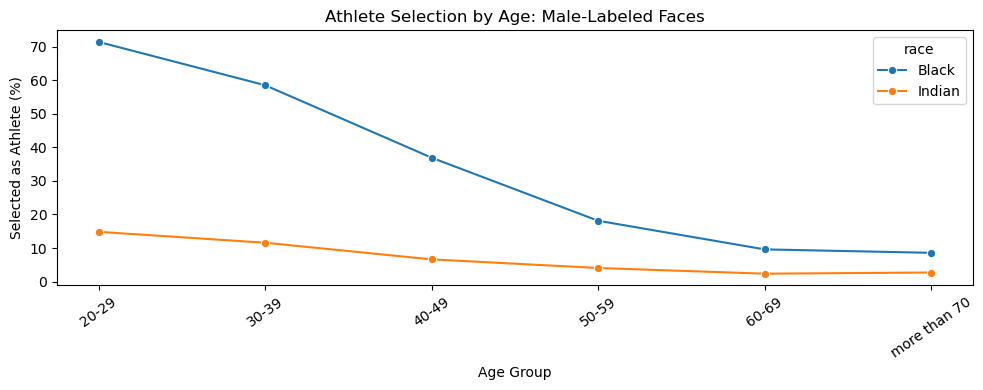

In [19]:

# Investigate athlete predictions by ethnicity, age and gender

focus = results[
    results["race"].isin(["Black", "Indian"])
].copy()

focus["athlete_selected"] = (
    focus["predicted_job"] == "athlete"
).astype(int)

athlete_age = focus.groupby(
    ["gender", "race", "age"]
)["athlete_selected"].agg(
    rate="mean",
    count="size"
).reset_index()

athlete_age["percentage"] = athlete_age["rate"] * 100

age_order = list(dataset.features["age"].names)

athlete_age["age"] = pd.Categorical(
    athlete_age["age"],
    categories=age_order,
    ordered=True
)

# Avoid drawing conclusions from very small groups
athlete_age = athlete_age[
    athlete_age["count"] >= 30
].sort_values("age")

display(athlete_age.round(1))

for gender in ["Female", "Male"]:

    subset = athlete_age[
        athlete_age["gender"] == gender
    ]

    plt.figure(figsize=(10, 4))

    sns.lineplot(
        data=subset,
        x="age",
        y="percentage",
        hue="race",
        marker="o"
    )

    plt.title(
        f"Athlete Selection by Age: {gender}-Labeled Faces"
    )
    plt.xlabel("Age Group")
    plt.ylabel("Selected as Athlete (%)")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()


### Interpretation: Athlete Predictions Across Age, Gender, and Ethnicity

The results show that CLIP selects "athlete" more often for Black-labeled faces than Indian-labeled faces across the age groups we compared.

For example, among male-labeled faces aged 20–29, CLIP selected athlete for 71.5% of Black-labeled faces, compared with only 14.8% of Indian-labeled faces.

For female-labeled faces of the same age, the percentages were 35.8% and 9.1%.

The association also changes with age. Among Black-labeled male faces, athlete selection decreases from 71.5% at ages 20–29 to 36.9% at ages 40–49.

**Conclusion:** The ethnicity difference does not disappear when we compare people of similar ages and the same gender label. However, its size changes with age. This suggests that age, gender, and ethnicity-related visual patterns may interact in CLIP's occupation associations. It does not explain what causes these differences.

## Study one occupation more deeply

In [20]:
##Study one occupation more deeply
##Let's investigate the occupation engineer.

##Maybe it shows a gender difference. Maybe it does not.

##First, calculate how often CLIP chooses engineer for every gender and ethnicity combination.


results["chose_engineer"] = (
    results["predicted_job"] == "engineer"
).astype(int)

engineer_groups = results.groupby(
    ["race", "gender"]
)["chose_engineer"].agg(
    rate="mean",
    count="size"
).reset_index()

engineer_groups["percentage"] = (
    engineer_groups["rate"] * 100
)

display(engineer_groups)


,race,gender,rate,count,percentage
0,Black,Female,0.004907,4891,0.490697
1,Black,Male,0.080968,4545,8.096810
2,East Asian,Female,0.012689,5280,1.268939
3,East Asian,Male,0.215011,4823,21.501140
4,Indian,Female,0.023319,4803,2.331876
5,Indian,Male,0.525937,5417,52.593687
6,Latino_Hispanic,Female,0.005130,5458,0.513008
7,Latino_Hispanic,Male,0.191697,5733,19.169719
8,Middle Eastern,Female,0.008287,2534,0.828729
9,Middle Eastern,Male,0.241379,6090,24.137931


How to read the detailed engineer table
- percentage is how often CLIP selected engineer in one gender × ethnicity group.
- count tells you how many faces were used for that percentage.
The data show very different subgroup results: for Indian-labeled faces, 52.6% of male-labeled and 2.3% of female-labeled faces are called engineer. For Black-labeled faces, the corresponding values are 8.1% and 0.5%. These are not equal-sized differences. The intersection of both labels matters.

This is a reason to go deeper instead of stopping at the overall gender chart. It does not mean any person in these groups really has that occupation.

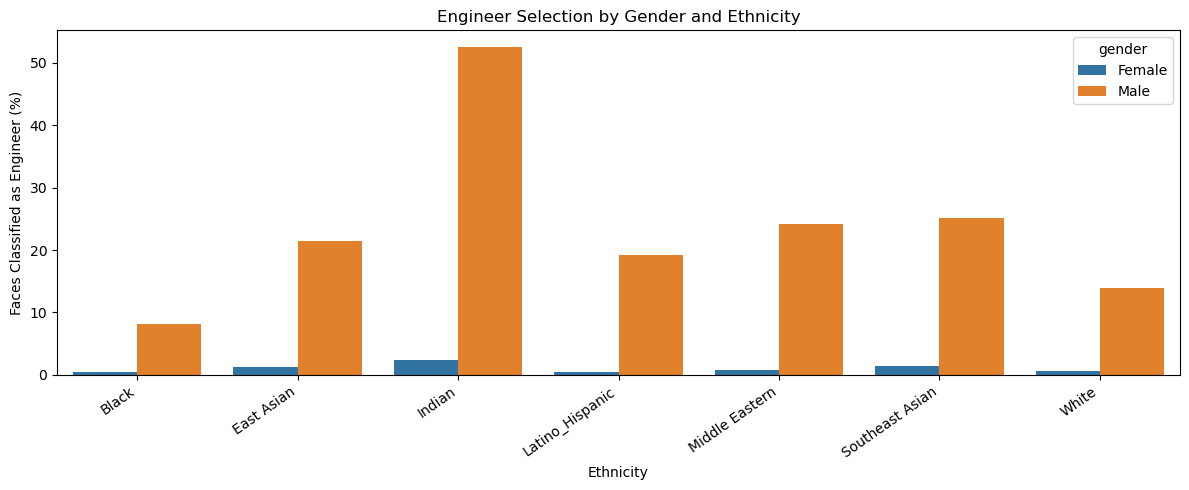

In [21]:

plt.figure(figsize=(12, 5))

sns.barplot(
    data=engineer_groups,
    x="race",
    y="percentage",
    hue="gender"
)

plt.title("Engineer Selection by Gender and Ethnicity")
plt.xlabel("Ethnicity")
plt.ylabel("Faces Classified as Engineer (%)")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.savefig("engineer_subgroups.png", dpi=200)
plt.show()


Engineer: the gender difference depends on ethnicity
The engineer bar chart is not showing a single fixed “male effect.” In the saved results:
- Indian: male-labeled 52.6%, female-labeled 2.3% (50.3-point gap).
- Black: male-labeled 8.1%, female-labeled 0.5% (7.6-point gap).
- Middle Eastern: male-labeled 24.1%, female-labeled 0.8% (a large difference, but check the number of faces and rounding).
What does this tell us? The gender gap is present in many groups, but its size is not the same everywhere. A useful new question is: Why is the engineer association especially strong for Indian male-labeled faces? Possible things to test include age, glasses, clothing and differences in image style. These are hypotheses, not proven explanations.

The later glasses experiment tests one of these ideas across a separately selected sample.

# Does age change the engineer association?
The next graph separates the model's engineer choices by age group and gender. We want to see whether the difference happens at every age, or mostly in some age groups.

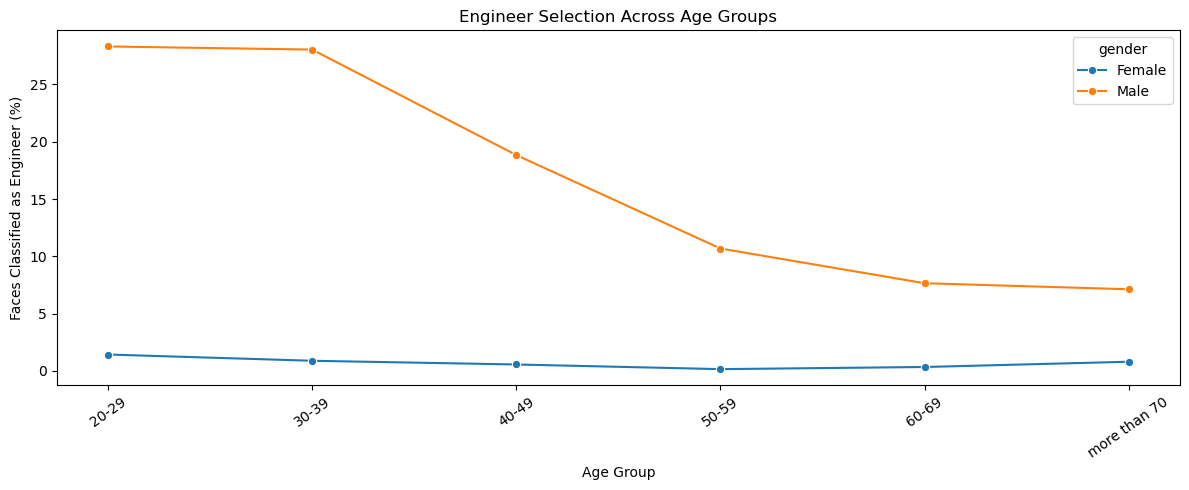

In [22]:

age_order = list(dataset.features["age"].names)

age_results = results.groupby(
    ["age", "gender"]
)["chose_engineer"].agg(
    percentage="mean",
    count="size"
).reset_index()

age_results["percentage"] *= 100

age_results["age"] = pd.Categorical(
    age_results["age"],
    categories=age_order,
    ordered=True
)

age_results = age_results.sort_values(
    ["gender", "age"]
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=age_results,
    x="age",
    y="percentage",
    hue="gender",
    marker="o",
    sort=False
)

plt.title("Engineer Selection Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Faces Classified as Engineer (%)")
plt.xticks(rotation=35)

plt.tight_layout()
plt.savefig("age_comparison.png", dpi=200)
plt.show()


Engineer across age groups
The male-labeled line reaches its highest point at roughly 28% for ages 20–29 and remains around 28% for ages 30–39. For female-labeled faces, engineer stays around 0–1.5% across the plotted age groups. The difference is especially big among adults aged about 20–39.

Why is that interesting? Age appears to change how strongly CLIP connects male-labeled faces to “engineer.” This means the overall gender chart hides differences between younger and older groups. The smallest and oldest age categories may have fewer faces, so a sharp change there should not be over-interpreted.

Next check: Compare male- and female-labeled faces within the same age and ethnicity groups. That reduces (but does not remove) these possible explanations.

# Reliability check — Could the engineer gap be a coincidence?
A bootstrap repeatedly takes random samples from the saved results and recalculates the gender difference. If the estimated difference stays far away from zero, that is stronger evidence that the pattern is systematic in this dataset.

In [23]:

male = results.loc[
    results["gender"] == "Male",
    "chose_engineer"
].to_numpy()

female = results.loc[
    results["gender"] == "Female",
    "chose_engineer"
].to_numpy()

observed_difference = (
    male.mean() - female.mean()
) * 100

rng = np.random.default_rng(42)

differences = []

for _ in range(2000):
    male_sample = rng.choice(
        male, size=len(male), replace=True
    )
    female_sample = rng.choice(
        female, size=len(female), replace=True
    )

    difference = (
        male_sample.mean() -
        female_sample.mean()
    ) * 100

    differences.append(difference)

lower, upper = np.percentile(
    differences, [2.5, 97.5]
)

print("Observed difference:", round(observed_difference, 2))
print("95% bootstrap interval:", round(lower, 2), "to", round(upper, 2))


Observed difference: 22.1
95% bootstrap interval: 21.66 to 22.54


The engineer gap is stable in this dataset
- Observed gap: 22.1 percentage points (male minus female).
- 95% bootstrap interval: 21.66 to 22.54 percentage points.
The interval does not contain zero. This means the difference is unlikely to come from a few lucky pictures alone, under this resampling method. It does not prove why CLIP made these choices. Bootstrap uncertainty also does not fix problems with how the pictures were collected or labeled.

Compare people within similar age and ethnicity groups

In [24]:

subgroup = results.groupby(
    ["race", "age", "gender"]
)["chose_engineer"].agg(
    rate="mean",
    count="size"
).reset_index()

rates = subgroup.pivot(
    index=["race", "age"],
    columns="gender",
    values="rate"
)

counts = subgroup.pivot(
    index=["race", "age"],
    columns="gender",
    values="count"
)

valid = (
    (counts["Male"] >= 10) &
    (counts["Female"] >= 10)
)

if valid.any():
    differences = (
        rates.loc[valid, "Male"] -
        rates.loc[valid, "Female"]
    )

    weights = counts.loc[
        valid, ["Male", "Female"]
    ].sum(axis=1)

    adjusted_difference = np.average(
        differences,
        weights=weights
    ) * 100

    print(
        "Difference after comparing age/ethnicity groups:",
        round(adjusted_difference, 2),
        "percentage points"
    )
    print("Groups compared:", valid.sum())
else:
    print("Not enough pictures in the subgroups.")


Difference after comparing age/ethnicity groups: 22.64 percentage points
Groups compared: 42


The engineer gap remains after a basic subgroup comparison
The age × ethnicity comparison gives a weighted gender gap of 22.64 percentage points across 42 eligible subgroups. This is close to the unadjusted result of 22.1 points.

Why does that matter? The overall engineer difference does not disappear when we compare images from the same age and ethnicity categories. That makes the pattern more convincing as a model association. However, this is still not a controlled experiment: differences in glasses, lighting, hairstyle, or clothing may remain.

# Investigate the pictures themselves

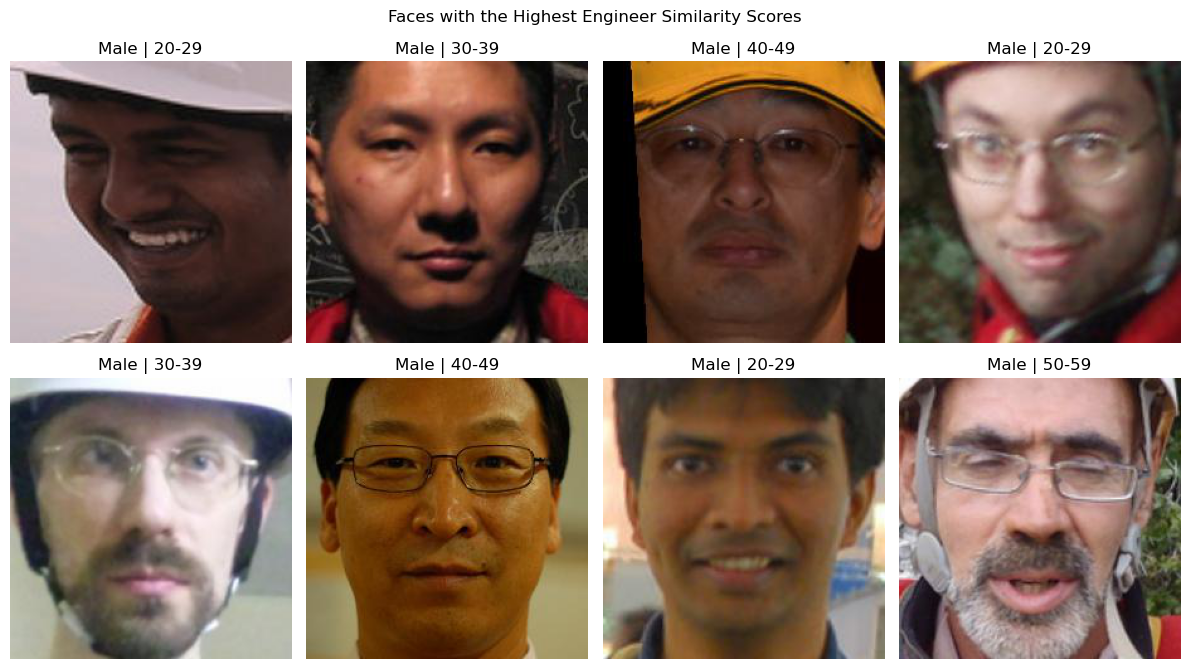

In [25]:
##Find pictures that CLIP strongly connects with "engineer"

examples = results.nlargest(
    8, "sim_engineer"
)

fig, axes = plt.subplots(2, 4, figsize=(12, 7))

for ax, (_, row) in zip(axes.flat, examples.iterrows()):

    face = dataset[
        int(row["image_index"])
    ]["image"]

    ax.imshow(face)
    ax.set_title(
        f"{row['gender']} | {row['age']}"
    )
    ax.axis("off")

plt.suptitle(
    "Faces with the Highest Engineer Similarity Scores"
)

plt.tight_layout()
plt.savefig("engineer_examples.png", dpi=200)
plt.show()


What the strongest engineer examples look like
In the saved grid of the eight highest engineer-similarity faces:
- All eight have the FairFace Male label.
- Two out of eight have the age label 40–49. The other six are in the 20–29, 30–39, and 50–59 groups.
- Several are visibly wearing glasses.
This is a useful clue. Could glasses make a face look more similar to words such as engineer, scientist, or professor in CLIP's embedding space?

But do not jump to a conclusion: We chose these eight pictures because they already had very high engineer scores. They are not a random sample. To test glasses properly, we later use labels from a separate set of 315 images and compare the results. That is a much better way to investigate the idea.

Research question — Does changing only the words change CLIP's answers?
CLIP compares each photo with a list of sentences. We try three ways of describing the same eight jobs:
1. “A portrait photo of a …”
2. “A photo of a person whose job is a …”
3. “A photo of someone working as a …”

The pictures and the model do not change. Only the sentences change. So a difference here shows prompt sensitivity.

In [26]:

def article(job):
    return "an" if job[0].lower() in "aeiou" else "a"

prompt_versions = {
    "portrait": [
        f"a portrait photo of {article(j)} {j}"
        for j in occupations
    ],
    "person": [
        f"a photo of a person whose job is {article(j)} {j}"
        for j in occupations
    ],
    "working": [
        f"a photo of someone working as {article(j)} {j}"
        for j in occupations
    ]
}

prompt_rows = []

for version, descriptions in prompt_versions.items():

    inputs = processor(
        text=descriptions,
        return_tensors="pt",
        padding=True
    )

    inputs = {
        k: v.to(device)
        for k, v in inputs.items()
    }

    with torch.inference_mode():
        features = get_features_tensor(
            model.get_text_features(**inputs)
        )
        features = F.normalize(features, dim=-1)

    text_vectors = features.cpu().numpy()

    scores = image_embeddings @ text_vectors.T

    predictions = np.array(occupations)[
        scores.argmax(axis=1)
    ]

    agreement = (
        predictions == results["predicted_job"].to_numpy()
    ).mean() * 100

    print(
        version,
        "agreement with original:",
        round(agreement, 1),
        "%"
    )

    for gender in ["Male", "Female"]:
        mask = results["gender"].to_numpy() == gender

        engineer_rate = (
            predictions[mask] == "engineer"
        ).mean() * 100

        prompt_rows.append({
            "prompt": version,
            "gender": gender,
            "engineer_percent": engineer_rate
        })

prompt_results = pd.DataFrame(prompt_rows)

display(prompt_results)


portrait agreement with original: 100.0 %
person agreement with original: 60.3 %
working agreement with original: 57.1 %


,prompt,gender,engineer_percent
0,portrait,Male,23.127697
1,portrait,Female,1.030086
2,person,Male,13.229246
3,person,Female,1.304386
4,working,Male,1.348058
5,working,Female,0.099215


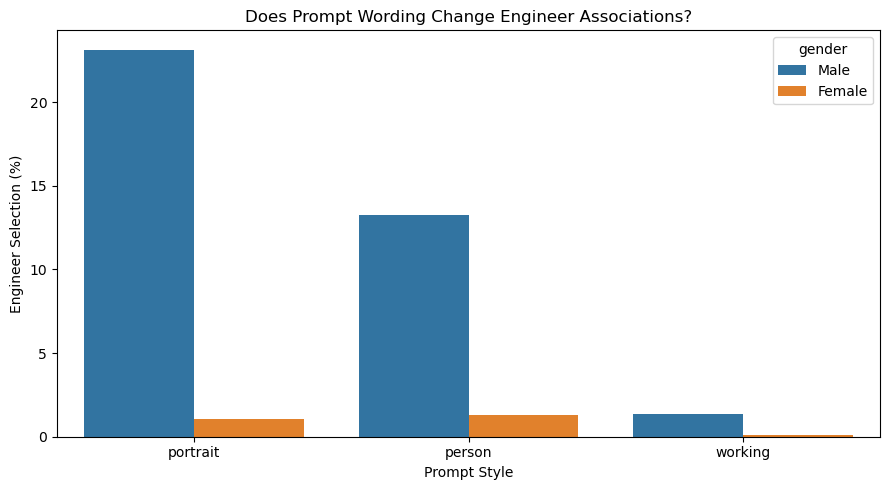

In [27]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=prompt_results,
    x="prompt",
    y="engineer_percent",
    hue="gender"
)

plt.title("Does Prompt Wording Change Engineer Associations?")
plt.ylabel("Engineer Selection (%)")
plt.xlabel("Prompt Style")

plt.tight_layout()
plt.savefig("prompt_sensitivity.png", dpi=200)
plt.show()


CLIP is very sensitive to how we ask

Does changing the sentence change CLIP's answer?

Yes. The actual saved results show a large change:
- With the original portrait sentence, agreement is 100% (we are comparing the same sentences to themselves).
- With "a photo of a person whose job is ...", only 60.3% of faces keep the same top occupation.
- With "a photo of someone working as ...", only 57.1% keep the same top occupation.
So the selected job changes for about two in five faces when we change just the words. This shows that CLIP's answers depend a lot on prompt wording.

When we rewrite the sentence, about 40–43% of faces receive a different top occupation. The picture has not changed, but the answer often does.

For engineer, the male-labeled percentage changes from 23.13% → 13.23% → 1.35%, while the female-labeled percentage changes from 1.03% → 1.30% → 0.10%. The gender difference becomes smaller in absolute percentage points, but it does not disappear in these three tests.

Why might this happen? "Someone working as an engineer" describes a work scene, but our pictures are portraits. That wording may fit a portrait less well. Also, CLIP must pick the best of the same eight occupations, so changes to one description can change which job wins.

Conclusion: Prompt wording is part of the model behavior. A useful fairness result should say which prompts were used, and ideally should test more than one style.

# Check whether uncertain predictions change more often

,prompt,margin_group,changed_percent,count
0,person,Very small,60.4,18415
1,person,Small,50.3,18415
2,person,Large,35.4,18414
3,person,Very large,12.7,18415
4,working,Very small,60.3,18415
5,working,Small,51.9,18415
6,working,Large,39.1,18414
7,working,Very large,20.4,18415


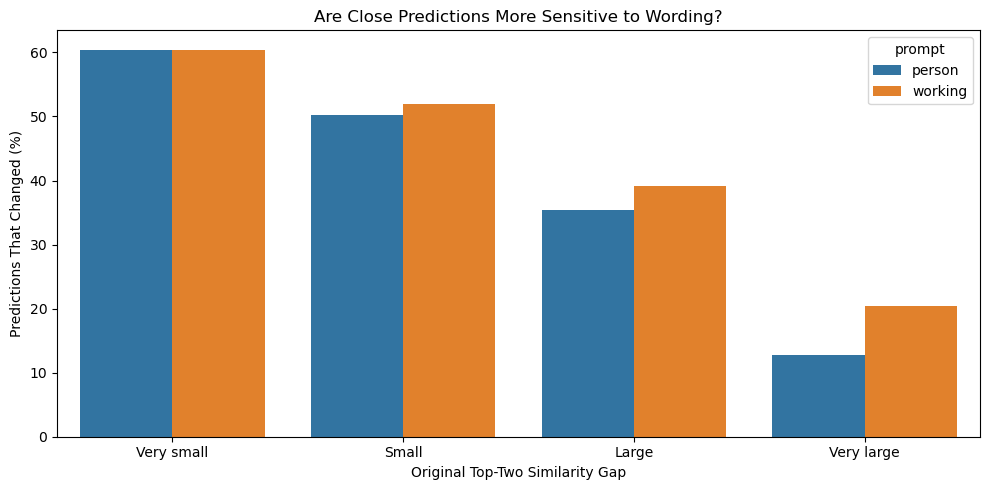

In [28]:

# Check whether uncertain predictions change more often

sorted_scores = np.sort(similarities, axis=1)

# Difference between highest and second-highest score
margin = sorted_scores[:, -1] - sorted_scores[:, -2]

margin_groups = pd.qcut(
    margin,
    4,
    labels=["Very small", "Small", "Large", "Very large"]
)

change_rows = []

for version in ["person", "working"]:

    descriptions = prompt_versions[version]

    inputs = processor(
        text=descriptions,
        return_tensors="pt",
        padding=True
    )

    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.inference_mode():
        features = get_features_tensor(
            model.get_text_features(**inputs)
        )
        features = F.normalize(features, dim=-1)

    new_scores = image_embeddings @ features.cpu().numpy().T

    new_predictions = np.array(occupations)[
        new_scores.argmax(axis=1)
    ]

    changed = (
        new_predictions != results["predicted_job"].to_numpy()
    )

    temp = pd.DataFrame({
        "margin_group": margin_groups,
        "changed": changed
    })

    summary = temp.groupby(
        "margin_group", observed=True
    )["changed"].agg(["mean", "size"]).reset_index()

    for _, row in summary.iterrows():
        change_rows.append({
            "prompt": version,
            "margin_group": row["margin_group"],
            "changed_percent": row["mean"] * 100,
            "count": row["size"]
        })

change_table = pd.DataFrame(change_rows)
display(change_table.round(1))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=change_table,
    x="margin_group",
    y="changed_percent",
    hue="prompt"
)

plt.title("Are Close Predictions More Sensitive to Wording?")
plt.xlabel("Original Top-Two Similarity Gap")
plt.ylabel("Predictions That Changed (%)")

plt.tight_layout()
plt.savefig("prompt_margin_analysis.png", dpi=200)
plt.show()


### Interpretation: Why do some predictions change when the prompt changes?

The results show that CLIP is more likely to change its prediction when the two highest occupation scores are close together.

For the **person prompt**, 60.4% of predictions changed in the very-small-margin group, compared with only 12.7% in the very-large-margin group.

The **working prompt** showed a similar pattern: 60.3% changed in the very-small-margin group, compared with 20.4% in the very-large-margin group.

This suggests that when CLIP gives two occupations similar scores, small changes in wording can easily change which occupation wins.

**Conclusion:** CLIP's predictions are less stable when the competing occupations have similar scores. However, even predictions with large margins can change when the prompt changes.

# Optional deeper test: compare all jobs, not only engineer.

In [29]:
# Optional deeper test: compare all jobs, not only engineer.
# Uses saved image embeddings; does NOT process the face images again.
all_prompt_rows = []
for version, descriptions in prompt_versions.items():
    batch = processor(text=descriptions, return_tensors="pt", padding=True)
    batch = {k: v.to(device) for k, v in batch.items()}
    with torch.inference_mode():
        vectors = get_features_tensor(model.get_text_features(**batch))
        vectors = F.normalize(vectors, dim=-1).cpu().numpy()
    chosen = np.array(occupations)[(image_embeddings @ vectors.T).argmax(axis=1)]
    for gender in ["Female", "Male"]:
        mask = results["gender"].to_numpy() == gender
        for job in occupations:
            all_prompt_rows.append({"prompt": version, "gender": gender,
                                    "occupation": job,
                                    "selected_percent": 100*(chosen[mask] == job).mean()})

prompt_all_jobs = pd.DataFrame(all_prompt_rows)
for gender in ["Female", "Male"]:
    display(prompt_all_jobs[prompt_all_jobs.gender == gender].pivot(
        index="occupation", columns="prompt", values="selected_percent"
    ).round(1))

prompt,person,portrait,working
occupation,,,
artist,8.7,12.0,4.8
athlete,3.2,12.8,4.7
doctor,3.7,0.1,0.6
engineer,1.3,1.0,0.1
nurse,29.1,16.8,7.7
professor,6.1,2.4,1.2
scientist,2.3,0.3,0.2
teacher,45.5,54.6,80.8


prompt,person,portrait,working
occupation,,,
artist,10.9,9.7,5.3
athlete,17.9,25.6,14.9
doctor,7.5,3.1,3.2
engineer,13.2,23.1,1.3
nurse,3.7,0.6,0.6
professor,4.5,14.2,7.3
scientist,7.0,0.7,0.7
teacher,35.2,22.9,66.6


Extra prompt result — “Teacher” becomes the default for many faces
The full occupation tables (not just engineer) show another strong effect:
- For female-labeled faces, teacher changes from 54.6% with the portrait prompt to 45.5% with the person prompt and 80.8% with the working prompt.
- For male-labeled faces, teacher changes from 22.9% → 35.2% → 66.6%.
What does that tell us? With “someone working as …”, CLIP chooses teacher for the majority of faces in both gender groups, even though no photo changed. The prompt wording changes the overall distribution of occupations, not just a few isolated predictions. This is a reason to avoid calling a single prompt the model's one “true opinion.”

What does CLIP's image–text embedding space show?

We use PCA to draw a simple two-dimensional picture of that space. PCA is a summary map: it cannot keep every detail from all 512 numbers.

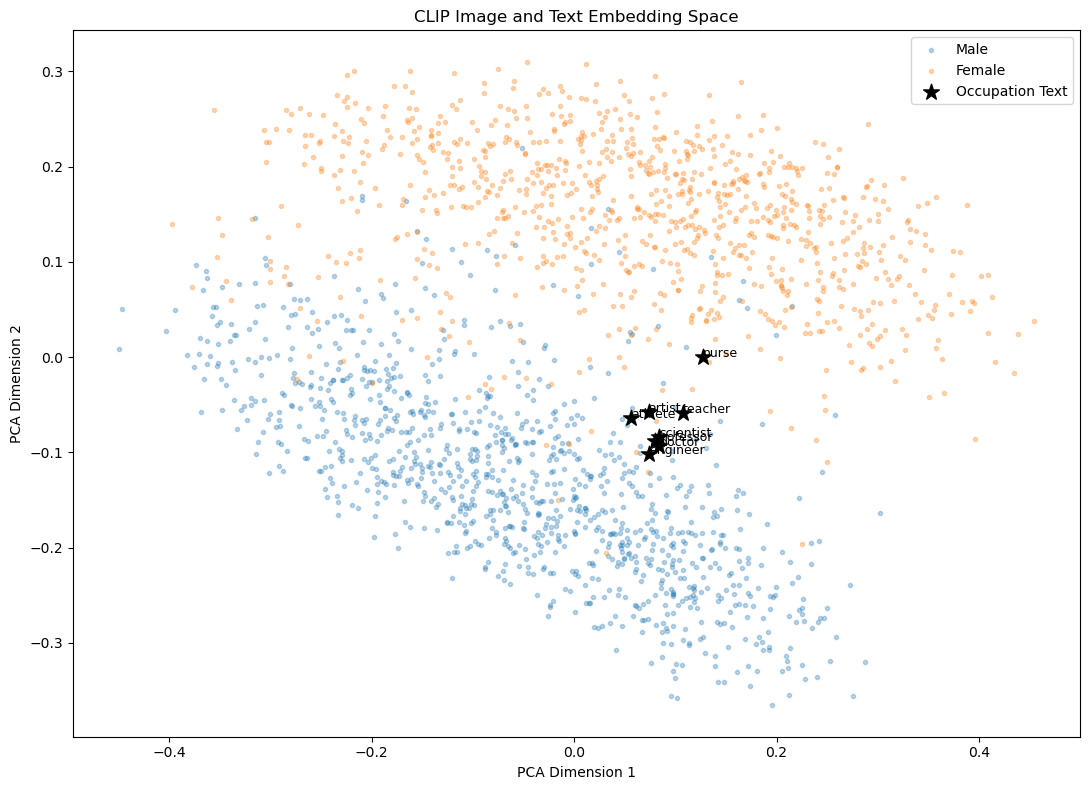

In [30]:

n_show = min(2000, len(results))

combined = np.vstack([
    image_embeddings[:n_show],
    text_embeddings
])

pca = PCA(n_components=2, random_state=42)

coordinates = pca.fit_transform(combined)

face_points = coordinates[:n_show]
job_points = coordinates[n_show:]

face_genders = results["gender"].iloc[
    :n_show
].to_numpy()

plt.figure(figsize=(11, 8))

for gender in ["Male", "Female"]:

    mask = face_genders == gender

    plt.scatter(
        face_points[mask, 0],
        face_points[mask, 1],
        s=9,
        alpha=0.3,
        label=gender
    )

plt.scatter(
    job_points[:, 0],
    job_points[:, 1],
    color="black",
    marker="*",
    s=140,
    label="Occupation Text"
)

for i, job in enumerate(occupations):
    plt.annotate(
        job,
        (job_points[i, 0], job_points[i, 1]),
        fontsize=9
    )

plt.title("CLIP Image and Text Embedding Space")
plt.xlabel("PCA Dimension 1")
plt.ylabel("PCA Dimension 2")
plt.legend()

plt.tight_layout()
plt.savefig("embedding_plot.png", dpi=200)
plt.show()


Interpretation of PCA embedding map
Remember: every small circle is one face (only the first 2,000 selected faces are plotted), and every black star is one job sentence.
- Do faces with the same gender label form groups? Partly. Many orange female-labeled points are higher on the plot, and many blue male-labeled points are lower. This suggests that gender-related information is present in the image embeddings.
- Is there overlap? Yes. Male- and female-labeled points mix across the center. They do not form two separate islands.
- Are the job descriptions in different areas? The black stars appear close together in one small area, rather than in eight clearly separated clusters. Their names overlap on the chart.
- Are image and text points far apart? The text stars sit near one part of the cloud but are much more tightly packed than the face points. We cannot use these 2D distances to decide which occupation an image is closest to in the original space.
What this means: The image embeddings appear to carry some gender-related structure, but the PCA plot by itself does not explain a teacher/athlete/engineer decision. PCA keeps only two of the original 512 dimensions. Two points can look close here even if they are not especially close in the full model space.

To investigate the actual CLIP scoring space, the occupation-alignment graph below uses the original 512-dimensional embeddings, not just their 2D drawing.

In [31]:
# How much of the original 512-dimensional variation can we see in the 2D map?
print("PCA dimension 1 explains:", f"{pca.explained_variance_ratio_[0]*100:.1f}%")
print("PCA dimension 2 explains:", f"{pca.explained_variance_ratio_[1]*100:.1f}%")
print("Both dimensions together explain:",
      f"{pca.explained_variance_ratio_.sum()*100:.1f}%")

# Compare the average vertical (PCA 2) position by gender for the 2,000 shown faces.
pca_groups = pd.DataFrame({
    "gender": face_genders,
    "PC1": face_points[:, 0],
    "PC2": face_points[:, 1]
})
display(pca_groups.groupby("gender")[["PC1", "PC2"]].mean().round(3))

PCA dimension 1 explains: 8.8%
PCA dimension 2 explains: 8.1%
Both dimensions together explain: 16.9%


,PC1,PC2
gender,,
Female,0.062,0.146
Male,-0.054,-0.127


How much of CLIP's space is visible in this drawing?
PCA dimension 1 explains 8.8% of the variation and dimension 2 explains 8.1%. Together, the 2D drawing keeps 16.9% of the variation in the embeddings used for this plot.

That means 83.1% is outside this drawing. The map is useful for noticing broad structure and overlap, but it is not a trustworthy ruler for exact CLIP image–text distances. That is why we compare original cosine similarities in the next section. The group centers in the two-dimensional map differ, but this alone is not a test of bias or cause.

Deeper embedding test — Compare the original 512-dimensional scores
Here we compare the average similarity of each occupation sentence with male- versus female-labeled image embeddings. Unlike PCA, this uses all 512 dimensions. A positive bar means higher average similarity for the male-labeled group; a negative bar means higher average similarity for the female-labeled group.

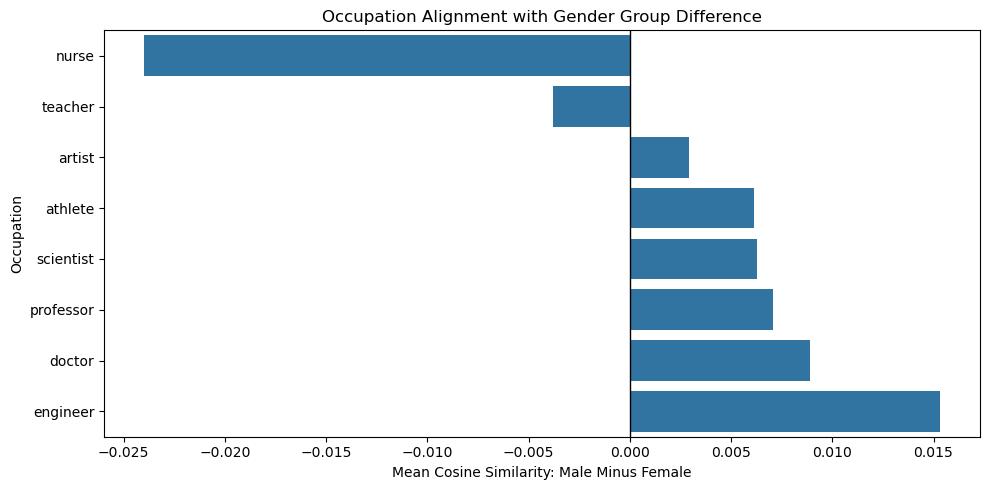

In [32]:

male_mask = (
    results["gender"].to_numpy() == "Male"
)

female_mask = (
    results["gender"].to_numpy() == "Female"
)

male_center = image_embeddings[male_mask].mean(axis=0)
female_center = image_embeddings[female_mask].mean(axis=0)

gender_direction = male_center - female_center

occupation_alignment = (
    text_embeddings @ gender_direction
)

alignment_table = pd.DataFrame({
    "occupation": occupations,
    "male_minus_female": occupation_alignment
})

alignment_table = alignment_table.sort_values(
    "male_minus_female"
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=alignment_table,
    x="male_minus_female",
    y="occupation"
)

plt.axvline(0, color="black", linewidth=1)

plt.title("Occupation Alignment with Gender Group Difference")
plt.xlabel("Mean Cosine Similarity: Male Minus Female")
plt.ylabel("Occupation")

plt.tight_layout()
plt.savefig("embedding_alignment.png", dpi=200)
plt.show()


What the occupation-alignment graph adds
The graph uses the original 512-dimensional CLIP similarity scores, rather than the flat PCA drawing.
- Nurse and teacher point toward the female-labeled side (negative values).
- Engineer has the strongest positive value, toward the male-labeled side.
- Athlete, doctor, and professor also point toward the male-labeled side.
The direction of these bars agrees with several patterns in the original heatmap. This is important: the association can be seen inside the shared image–text space, not only after choosing one occupation as the winner.

The values are differences in average cosine similarity, not percentages, and they are not claims about anyone's true occupation. The image embeddings can also contain age, hairstyle, glasses, and other visual information, so this does not isolate a single cause.

# Investigate different regions of the PCA map

In [33]:

# Investigate different regions of the PCA map

pca_analysis = results.iloc[:n_show].copy()

pca_analysis["PC2"] = face_points[:, 1]

pca_analysis["region"] = pd.qcut(
    pca_analysis["PC2"],
    4,
    labels=[
        "Bottom",
        "Lower middle",
        "Upper middle",
        "Top"
    ]
)

# Compare gender composition in each region
gender_regions = pd.crosstab(
    pca_analysis["region"],
    pca_analysis["gender"],
    normalize="index"
) * 100

print("Gender composition by PCA region:")
display(gender_regions.round(1))

# Compare original similarity scores
score_regions = pca_analysis.groupby(
    "region", observed=True
)[
    ["sim_teacher", "sim_engineer", "sim_athlete"]
].mean()

print("Mean occupation similarity scores by region:")
display(score_regions.round(3))

# Compare ethnicity composition
race_regions = pd.crosstab(
    pca_analysis["region"],
    pca_analysis["race"],
    normalize="index"
) * 100

print("Ethnicity composition by PCA region:")
display(race_regions.round(1))


Gender composition by PCA region:


gender,Female,Male
region,,
Bottom,0.6,99.4
Lower middle,8.8,91.2
Upper middle,78.0,22.0
Top,99.0,1.0


Mean occupation similarity scores by region:


,sim_teacher,sim_engineer,sim_athlete
region,,,
Bottom,0.257,0.256,0.249
Lower middle,0.251,0.251,0.250
Upper middle,0.257,0.239,0.244
Top,0.249,0.233,0.241


Ethnicity composition by PCA region:


race,Black,East Asian,Indian,Latino_Hispanic,Middle Eastern,Southeast Asian,White
region,,,,,,,
Bottom,11.4,5.8,21.0,18.0,19.0,6.0,18.8
Lower middle,14.8,11.8,12.4,12.0,12.4,13.6,23.0
Upper middle,15.6,12.6,18.4,16.4,5.8,11.8,19.4
Top,9.2,22.2,9.4,15.4,5.0,16.6,22.2


### Interpretation: Investigating Different PCA Regions

The PCA analysis shows that different regions of CLIP's embedding space contain different groups of faces.

In the bottom region, 99.4% of faces are male-labeled. In contrast, the top region contains 99.0% female-labeled faces.

The ethnicity composition also changes. East Asian-labeled faces increase from 5.8% in the bottom region to 22.2% in the top region.

The occupation similarity scores also vary across the regions. For example, the average engineer similarity decreases from 0.256 in the bottom region to 0.233 in the top region. Teacher similarity also decreases from 0.257 to 0.249.

This is interesting because the top region contains more female-labeled faces but does not have a higher average teacher similarity score. Therefore, the PCA position alone cannot explain the teacher association.

**Conclusion:** CLIP's image embeddings contain demographic-related patterns, but they are not completely separated. Different regions have different group compositions and occupation scores. Since PCA preserves only 16.9% of the variation in this visualization, we cannot use the 2D map alone to explain CLIP's predictions.

# New experiment: Do glasses change CLIP's occupation associations?
Why we need a new column
FairFace does not come with a "glasses" label. We must add one by looking at pictures. Do not invent labels or assume that someone wears glasses just because CLIP called them "engineer".

For a new labeling file, we take a random, balanced sample of 30 pictures from each of the 14 gender × ethnicity groups, which makes about 420 pictures. This gives each group a chance to be represented. For stronger evidence you can later increase this to 50 per group, but 420 is a reasonable start for a manual exercise. This run uses 315 existing adult labels.

For each picture, click:
- Yes = glasses are visibly worn (including sunglasses, if any).
- No = no glasses visible.
- Unsure = too hard to tell; exclude these from the comparison.
Only use what you can see, not what you imagine the person's job might be. Save your work often; the code below saves automatically after every click.

Important limitation: The labeled sample is not the same as the overall FairFace population. We will report counts and within-group rates and not treat these as population-wide percentages. Glasses can be related to age and other image details, so comparing glasses and no-glasses groups is not proof that glasses cause a CLIP prediction.

In [34]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

if "results" not in globals():
    saved_results = Path("clip_results.csv")
    if not saved_results.exists():
        raise FileNotFoundError("Please run the original CLIP experiment to create clip_results.csv first.")
    results = pd.read_csv(saved_results)

if "dataset" not in globals():
    dataset = load_dataset("HuggingFaceM4/FairFace", "0.25", split="validation")

if "occupations" not in globals():
    occupations = ["doctor", "nurse", "engineer", "scientist",
                   "professor", "teacher", "artist", "athlete"]

print("Loaded", len(results), "saved CLIP results. Ready to label glasses.")

Loaded 73659 saved CLIP results. Ready to label glasses.


In [35]:
# Create a balanced list of pictures to label, without losing work if re-run.
from pathlib import Path

GLASSES_PER_GROUP = 30    # 30 x 14 gender/ethnicity groups ~= 420 images
labels_path = Path("glasses_labels.csv")

if labels_path.exists():
    glasses_labels = pd.read_csv(labels_path)
    glasses_labels["glasses"] = glasses_labels["glasses"].fillna("Unlabeled")
    print("Loaded existing labels — your earlier work is kept.")
else:
    groups = []
    for _, group in results.groupby(["race", "gender"]):
        groups.append(group.sample(n=min(GLASSES_PER_GROUP, len(group)),
                                   random_state=42))
    chosen = pd.concat(groups).sample(frac=1, random_state=42)
    glasses_labels = chosen[["image_index", "gender", "race", "age"]].copy()
    glasses_labels["glasses"] = "Unlabeled"
    glasses_labels = glasses_labels.reset_index(drop=True)
    glasses_labels.to_csv(labels_path, index=False)
    print("Created a fresh, balanced labeling list.")

print("Total chosen:", len(glasses_labels))
print(glasses_labels["glasses"].value_counts())
display(glasses_labels.head())

Loaded existing labels — your earlier work is kept.
Total chosen: 315
glasses
No        257
Yes        57
Unsure      1
Name: count, dtype: int64


,image_index,gender,race,age,glasses
0,66774,Female,Indian,30-39,No
1,69350,Male,Southeast Asian,40-49,No
2,68570,Male,Indian,more than 70,No
3,65939,Female,White,20-29,No
4,68349,Female,East Asian,40-49,No


In [36]:
import ipywidgets as widgets
from IPython.display import display, clear_output

label_output = widgets.Output()
yes_button = widgets.Button(description="Yes — glasses", button_style="success")
no_button = widgets.Button(description="No glasses", button_style="info")
unsure_button = widgets.Button(description="Unsure", button_style="warning")

def show_next_photo():
    with label_output:
        clear_output(wait=True)
        undone = glasses_labels.index[glasses_labels["glasses"] == "Unlabeled"]
        finished = (glasses_labels["glasses"] != "Unlabeled").sum()
        print(f"Labeled {finished} of {len(glasses_labels)} pictures")
        if len(undone) == 0:
            print("Finished! Run the glasses analysis cells below.")
            for b in [yes_button, no_button, unsure_button]:
                b.disabled = True
        else:
            row = glasses_labels.loc[int(undone[0])]
            print("Image ID:", int(row["image_index"]))
            display(dataset[int(row["image_index"])]["image"])

def label_one(choice):
    undone = glasses_labels.index[glasses_labels["glasses"] == "Unlabeled"]
    if len(undone) == 0:
        return
    glasses_labels.loc[int(undone[0]), "glasses"] = choice
    glasses_labels.to_csv(labels_path, index=False)
    show_next_photo()

yes_button.on_click(lambda _: label_one("Yes"))
no_button.on_click(lambda _: label_one("No"))
unsure_button.on_click(lambda _: label_one("Unsure"))

display(widgets.HBox([yes_button, no_button, unsure_button]), label_output)
show_next_photo()

Output()

Pictures with clear Yes/No labels: 314
glasses
No     257
Yes     57
Name: count, dtype: int64


predicted_job,doctor,nurse,engineer,scientist,professor,teacher,artist,athlete
glasses,,,,,,,,
No,1.6,6.6,11.3,0.4,3.9,38.1,12.5,25.7
Yes,0.0,0.0,19.3,3.5,26.3,40.4,8.8,1.8


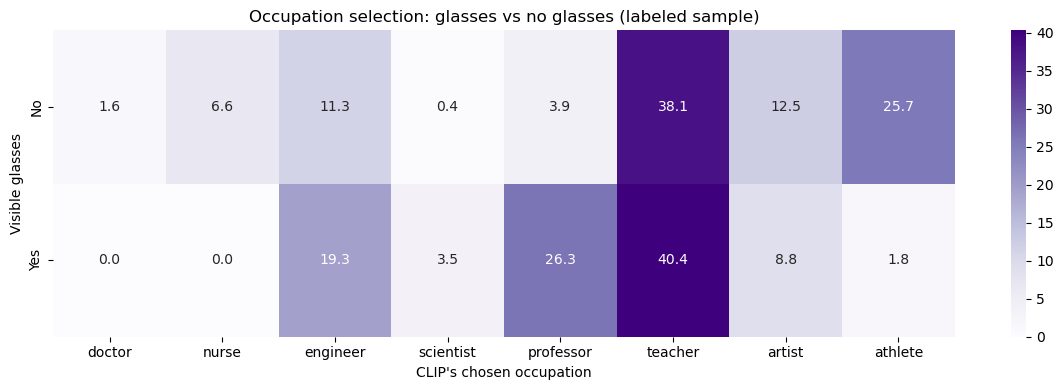

engineer: Glasses YES minus NO = +8.0 percentage points
scientist: Glasses YES minus NO = +3.1 percentage points
professor: Glasses YES minus NO = +22.4 percentage points
teacher: Glasses YES minus NO = +2.2 percentage points
athlete: Glasses YES minus NO = -23.9 percentage points


In [37]:
# Reload the saved labels so this cell works after restarting Jupyter.
glasses_labels = pd.read_csv("glasses_labels.csv")
seen_labels = glasses_labels.loc[
    glasses_labels["glasses"].isin(["Yes", "No"]),
    ["image_index", "glasses"]
].drop_duplicates("image_index")

glasses_results = results.merge(seen_labels, on="image_index", how="inner")

print("Pictures with clear Yes/No labels:", len(glasses_results))
print(glasses_results["glasses"].value_counts())

if glasses_results["glasses"].nunique() < 2:
    print("Need some Yes labels AND some No labels before comparing.")
else:
    glass_table = pd.crosstab(
        glasses_results["glasses"],
        glasses_results["predicted_job"],
        normalize="index"
    ).reindex(columns=occupations, fill_value=0) * 100
    display(glass_table.round(1))

    plt.figure(figsize=(12, 4))
    sns.heatmap(glass_table, annot=True, fmt=".1f", cmap="Purples")
    plt.title("Occupation selection: glasses vs no glasses (labeled sample)")
    plt.xlabel("CLIP's chosen occupation")
    plt.ylabel("Visible glasses")
    plt.tight_layout()
    plt.savefig("glasses_heatmap.png", dpi=200)
    plt.show()

    for job in ["engineer", "scientist", "professor", "teacher", "athlete"]:
        difference = glass_table.loc["Yes", job] - glass_table.loc["No", job]
        print(f"{job}: Glasses YES minus NO = {difference:+.1f} percentage points")

Glasses: the new measured result
You have 315 labeled adult images. 314 have a clear Yes/No label: 57 have visible glasses, 257 do not; one image is not included in the two-group comparison.

| Job selected by CLIP | Glasses **Yes** (n=57) | Glasses **No** (n=257) | Yes minus No |
|---|---:|---:|---:|
| **Professor** | **26.3%** | 3.9% | **+22.4 points** |
| **Engineer** | **19.3%** | 11.3% | **+8.0 points** |
| **Scientist** | **3.5%** | 0.4% | **+3.1 points** |
| **Teacher** | **40.4%** | 38.1% | **+2.2 points** |
| **Athlete** | **1.8%** | 25.7% | **−23.9 points** |

What stands out? CLIP picks academic jobs, particularly professor and engineer, more often for the glasses group. It picks athlete much less often. This matches the hypothesis suggested by the eight strongest engineer images, but now we are looking at a separate sample instead of cherry-picked high-scoring faces.

Do not overstate the small numbers. Only 2 glasses-wearing faces were selected as scientist, compared with 1 face without glasses. The scientist percentages sound different, but they are based on very few top-choice selections. Also, we only have 57 glasses images, so the glasses percentages are less stable than the larger no-glasses percentages.

Crucial: These are associations, not proof that glasses cause CLIP to choose any job. We now check whether the two groups also differ in demographic composition.

Make the glasses test fairer
Why we need this step: People with glasses might have a different age or gender mix from people without glasses. A simple percentage difference may come from those other differences instead of glasses.

First, we will count the groups. Then we will compare the actual cosine similarity scores, while statistically adjusting for age, gender, and ethnicity labels. This is called a controlled comparison.

What to look for: If a glasses difference remains after adjustment, that is stronger evidence of a systematic association. It still does not prove glasses caused it, because clothes, lighting, face pose, and other details are not controlled. Small samples can also give unstable answers.

In [38]:
# See whether the glasses and no-glasses groups contain different kinds of faces.
if glasses_results["glasses"].nunique() == 2:
    for field in ["gender", "age", "race"]:
        print("\nComposition by", field)
        print(pd.crosstab(glasses_results["glasses"],
                          glasses_results[field], normalize="index").mul(100).round(1))
else:
    print("Label more Yes and No pictures first.")


Composition by gender
gender   Female  Male
glasses              
No         52.5  47.5
Yes        33.3  66.7

Composition by age
age      20-29  30-39  40-49  50-59  60-69  more than 70
glasses                                                 
No        43.2   30.0   16.7    7.8    1.2           1.2
Yes       24.6   33.3   19.3   17.5    3.5           1.8

Composition by race
race     Black  East Asian  Indian  Latino_Hispanic  Middle Eastern  \
glasses                                                               
No        16.7        12.5    12.8             15.2            15.6   
Yes        8.8        21.1    17.5              5.3            15.8   

race     Southeast Asian  White  
glasses                          
No                  12.5   14.8  
Yes                 17.5   14.0  


The glasses groups are not the same kind of sample
The new composition tables reveal a possible source of confusion:
- 66.7% of the glasses group is male-labeled, versus 47.5% of the no-glasses group.
- 33.3% of the glasses group is labeled 30–39, versus 30.0% without glasses. Ages 50–59 are also more common with glasses (17.5% vs 7.8%).
- The ethnicity mix changes too: for example, East Asian-labeled faces are 21.1% of the glasses group and 12.5% of the no-glasses group.
Why does this matter? Earlier, engineer was already more common for male-labeled faces, especially at ages 20–39. So some of the apparent glasses difference might actually come from who happens to be in the glasses group.

Our next calculation adjusts the raw cosine similarity scores for the recorded age, gender, and ethnicity categories. It is a stronger association check, not a causal experiment.

,occupation,adjusted_glasses_similarity_difference,low_95_percent,high_95_percent
0,engineer,0.0080,0.0030,0.0129
1,scientist,0.0133,0.0069,0.0196
2,professor,0.0164,0.0111,0.0217
3,teacher,0.0112,0.0060,0.0164
4,athlete,-0.0022,-0.0059,0.0015


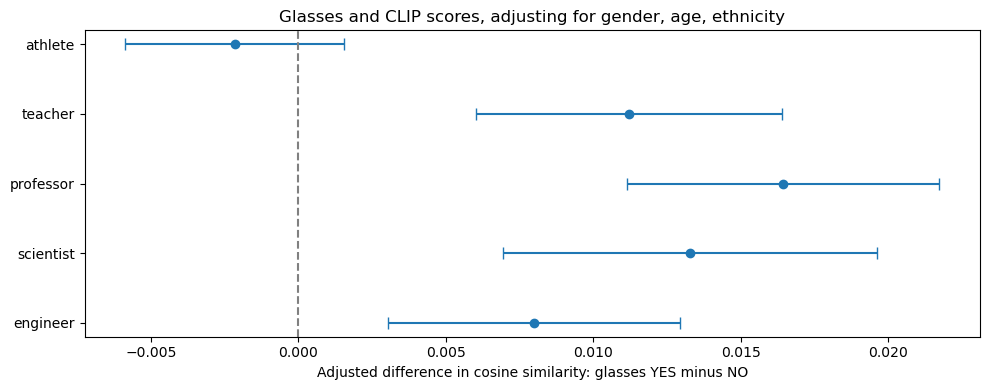

In [39]:
# A simple controlled comparison of the raw CLIP similarity scores.
# This needs statsmodels. If it is not installed, run: %pip install statsmodels
if (glasses_results["glasses"].nunique() == 2 and
    min(glasses_results["glasses"].value_counts()) >= 15):
    import statsmodels.formula.api as smf

    adjusted = glasses_results.copy()
    adjusted["glasses_yes"] = (adjusted["glasses"] == "Yes").astype(int)

    adjusted_rows = []
    for job in ["engineer", "scientist", "professor", "teacher", "athlete"]:
        fitted = smf.ols(
            f"sim_{job} ~ glasses_yes + C(gender) + C(age) + C(race)",
            data=adjusted
        ).fit(cov_type="HC3")
        low, high = fitted.conf_int().loc["glasses_yes"]
        adjusted_rows.append({
            "occupation": job,
            "adjusted_glasses_similarity_difference": fitted.params["glasses_yes"],
            "low_95_percent": low,
            "high_95_percent": high
        })

    adjusted_table = pd.DataFrame(adjusted_rows)
    display(adjusted_table.round(4))

    plt.figure(figsize=(10, 4))
    plt.errorbar(
        x=adjusted_table["adjusted_glasses_similarity_difference"],
        y=adjusted_table["occupation"],
        xerr=[
            adjusted_table["adjusted_glasses_similarity_difference"] - adjusted_table["low_95_percent"],
            adjusted_table["high_95_percent"] - adjusted_table["adjusted_glasses_similarity_difference"]
        ],
        fmt="o", capsize=4
    )
    plt.axvline(0, color="gray", linestyle="--")
    plt.xlabel("Adjusted difference in cosine similarity: glasses YES minus NO")
    plt.title("Glasses and CLIP scores, adjusting for gender, age, ethnicity")
    plt.tight_layout()
    plt.savefig("glasses_adjusted_scores.png", dpi=200)
    plt.show()
else:
    print("Label more faces. Need at least 15 clear Yes and 15 clear No cases.")

The glasses association after adjustment
The table above uses a regression model to compare the CLIP cosine similarity scores, with age, gender and ethnicity labels included as extra controls. Here, a positive number means the glasses group has a higher score after adjustment; negative means lower.

| Occupation | Adjusted glasses minus no-glasses score | 95% interval | Reading |
|---|---:|---:|---|
| **Professor** | **+0.0164** | +0.0111 to +0.0217 | A clear positive association in this fitted model |
| **Scientist** | **+0.0133** | +0.0069 to +0.0196 | A positive association, even though scientist rarely wins |
| **Teacher** | **+0.0112** | +0.0060 to +0.0164 | Positive association |
| **Engineer** | **+0.0080** | +0.0030 to +0.0129 | Positive association |
| **Athlete** | **−0.0022** | −0.0059 to +0.0015 | **Uncertain** because the interval includes zero |

Key result: The positive professor, scientist, teacher, and engineer score associations remain after statistical adjustment for the three recorded demographic labels. The athlete score result is not clearly different from zero after adjustment.

Why is the athlete result different from the raw heatmap? The heatmap asks “Which of eight jobs won?” The regression asks “How much did the original athlete similarity score change?” These are different questions. An occupation can lose as the top choice because another job's score grows, even if its own score barely changes.

Very important: These are cosine-similarity units, not percentages or probability points. The 95% intervals measure uncertainty under this regression model. They do not remove unmeasured differences such as clothing, lighting, hairstyle, or how glasses were labeled. We tested several occupations, so the results should be treated as exploratory, not final proof.

# Compare glasses effects inside each gender group

,gender,glasses,occupation,percentage,count
0,Female,Yes,professor,10.5,19
1,Female,Yes,engineer,0.0,19
2,Female,Yes,teacher,78.9,19
3,Female,Yes,athlete,0.0,19
4,Female,No,professor,0.0,135
5,Female,No,engineer,2.2,135
6,Female,No,teacher,49.6,135
7,Female,No,athlete,23.0,135
8,Male,Yes,professor,34.2,38
9,Male,Yes,engineer,28.9,38


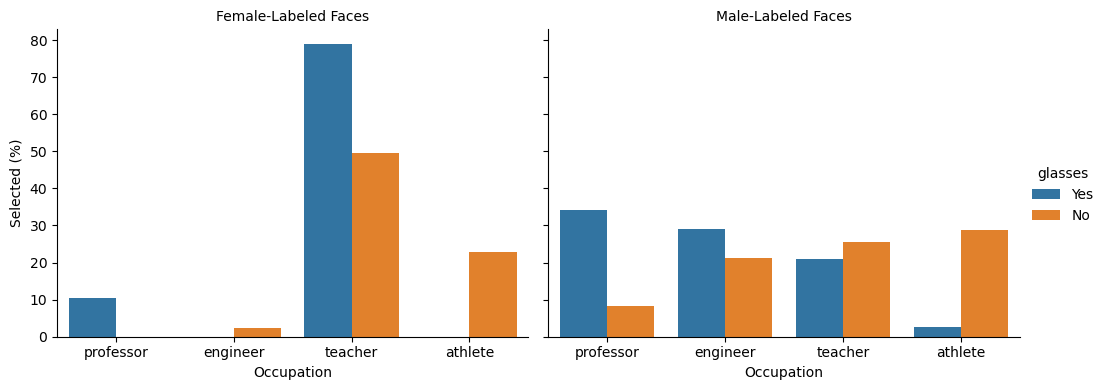

In [40]:

# Compare glasses effects inside each gender group

glasses_jobs = [
    "professor", "engineer", "teacher", "athlete"
]

glasses_gender_rows = []

for gender in ["Female", "Male"]:

    for glasses in ["Yes", "No"]:

        subset = glasses_results[
            (glasses_results["gender"] == gender) &
            (glasses_results["glasses"] == glasses)
        ]

        for job in glasses_jobs:

            percentage = (
                subset["predicted_job"] == job
            ).mean() * 100

            glasses_gender_rows.append({
                "gender": gender,
                "glasses": glasses,
                "occupation": job,
                "percentage": percentage,
                "count": len(subset)
            })

glasses_gender_table = pd.DataFrame(
    glasses_gender_rows
)

display(glasses_gender_table.round(1))

plot = sns.catplot(
    data=glasses_gender_table,
    x="occupation",
    y="percentage",
    hue="glasses",
    col="gender",
    kind="bar",
    height=4,
    aspect=1.3
)

plot.set_axis_labels(
    "Occupation",
    "Selected (%)"
)

plot.set_titles("{col_name}-Labeled Faces")

plt.show()


### Interpretation: Do Glasses Affect Occupation Predictions Within Gender Groups?

The results show that the association between glasses and occupations is different for male- and female-labeled faces.

For **female-labeled faces**, CLIP selected teacher for 78.9% of faces with glasses, compared with 49.6% without glasses. Professor also increased from 0.0% to 10.5%.

For **male-labeled faces**, professor increased from 8.2% without glasses to 34.2% with glasses. Engineer also increased from 21.3% to 28.9%.

Athlete showed the opposite pattern. For male-labeled faces, it decreased from 28.7% without glasses to 2.6% with glasses. For female-labeled faces, it decreased from 23.0% to 0.0%.

Interestingly, teacher selection among male-labeled faces decreased slightly from 25.4% without glasses to 21.1% with glasses.

**Conclusion:** Glasses are associated with different occupations, but the pattern depends on gender. Female-labeled faces with glasses are more often classified as teachers, while male-labeled faces with glasses are more often classified as professors and engineers.

However, the glasses sample contains only 19 female-labeled and 38 male-labeled faces with glasses. Therefore, the results need to be interpreted carefully. They show associations, not proof that glasses cause the predictions.

# What happens when we remove "nurse" or "athlete"?

For example, a face previously classified as "athlete" might become "engineer", even though the picture has not changed.

,menu,gender,teacher_percent
0,All 8 jobs,Female,54.644139
1,All 8 jobs,Male,22.896674
2,Without nurse,Female,67.326155
3,Without nurse,Male,23.214014
4,Without athlete,Female,59.905454
5,Without athlete,Male,29.324702
6,Without nurse or athlete,Female,75.418016
7,Without nurse or athlete,Male,29.776593


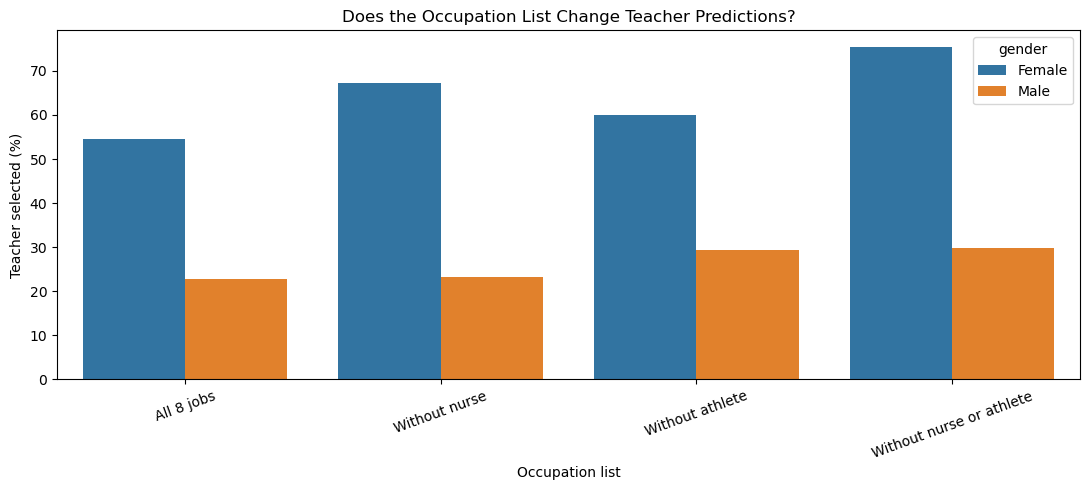

In [41]:
job_lists = {
    "All 8 jobs": occupations,
    "Without nurse": [
        j for j in occupations if j != "nurse"
    ],
    "Without athlete": [
        j for j in occupations if j != "athlete"
    ],
    "Without nurse or athlete": [
        j for j in occupations
        if j not in ["nurse", "athlete"]
    ]
}

menu_rows = []

for menu_name, jobs in job_lists.items():

    columns = [
        occupations.index(j) for j in jobs
    ]

    scores = similarities[:, columns]

    predictions = np.array(jobs)[
        scores.argmax(axis=1)
    ]

    for gender in ["Female", "Male"]:
        mask = results["gender"].to_numpy() == gender

        teacher_percent = (
            predictions[mask] == "teacher"
        ).mean() * 100

        menu_rows.append({
            "menu": menu_name,
            "gender": gender,
            "teacher_percent": teacher_percent
        })

menu_table = pd.DataFrame(menu_rows)

display(menu_table)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=menu_table,
    x="menu",
    y="teacher_percent",
    hue="gender"
)

plt.title("Does the Occupation List Change Teacher Predictions?")
plt.ylabel("Teacher selected (%)")
plt.xlabel("Occupation list")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

This experiment shows that CLIP's answers depend on which occupations we give it.

-When all eight occupations are available, CLIP chooses "teacher" for 54.6% of female-labeled faces and 22.9% of male-labeled faces.

-When we remove "nurse," the teacher percentage increases to 67.3% for female-labeled faces and 23.2% for male-labeled faces.

-When we remove both "nurse" and "athlete," teacher becomes the selected occupation for 75.4% of female-labeled faces and 29.8% of male-labeled faces.

Why does this happen?

-CLIP must choose the occupation with the highest similarity score from our list. When an occupation is removed, the same face may be assigned a different job.

-For example, removing "nurse" allows some faces previously classified as nurses to be classified as teachers instead.


What does this tell us about bias?

-The teacher gender gap does not disappear when the occupation list changes. However, its size changes from approximately 31.7 percentage points with all eight jobs to 45.6 points when both nurse and athlete are removed.

-This shows that the size of the measured association depends partly on the list of occupation descriptions.

-Conclusion: CLIP's occupation predictions are not fixed descriptions of people. They depend on the available choices. Fairness studies should therefore report which occupations were used and test whether findings remain similar when those choices change.

## Final Conclusion

This project investigated social biases in CLIP using **73,659 FairFace images** (age groups 20–29 and older) and eight occupation descriptions.

Our main findings are:

**Gender comparison:** CLIP selected teacher more often for female-labeled faces (54.6% versus 22.9%) and engineer more often for male-labeled faces (23.1% versus 1.0%).

**Ethnicity comparison:** Athlete was selected for 37.5% of Black-labeled faces, compared with 8.1% of Indian-labeled faces. Engineer showed the opposite pattern, with 29.0% for Indian-labeled faces versus 4.2% for Black-labeled faces. Scientist was rarely selected as the top occupation for any group.

**Age and subgroup analysis:** Engineer was particularly common among male-labeled adults aged 20–39. The gender difference remained around 22.6 percentage points after comparing similar age and ethnicity groups.

**Reliability test:** The engineer gender gap was 22.1 percentage points, with a 95% bootstrap interval of 21.66–22.54 points, suggesting a stable difference in our dataset.

**Face examples and glasses experiment:** Several high-engineer-similarity faces wore glasses. In our manually labeled sample, professor was selected for 26.3% of faces with glasses, compared with 3.9% without glasses. After statistical adjustment, professor, engineer, scientist, and teacher still showed positive glasses associations in their similarity scores. Further analysis showed that these patterns differed between gender groups.

**Prompt wording:** Changing the text descriptions caused approximately 40–43% of predictions to change. The prediction-margin experiment showed that faces with smaller score differences were more likely to receive a different occupation.

**Occupation-list experiment:** Removing nurse and athlete increased teacher selection for female-labeled faces from 54.6% to 75.4%, showing that CLIP's predictions depend on the available occupation choices.

**Embedding analysis:** The PCA visualization showed partial demographic separation, especially by gender. The original 512-dimensional similarity comparisons showed occupation associations consistent with several black-box results. Examining smaller PCA regions revealed differences in demographic composition and occupation scores, although the 2D visualization explained only 16.9% of the variation.

### Overall Finding

Our experiments show that CLIP's occupation associations vary systematically with demographic labels, visible features such as glasses, prompt wording, and the available occupations.

These patterns suggest that CLIP has learned associations that may reflect social stereotypes.

However, a face cannot reliably reveal someone's occupation. Our results describe the model's behavior, not people's actual jobs. They also do not prove what causes the associations.